<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 4: Breast Cancer Diagnosis: Develop a breast cancer classification model using medical imaging data (e.g., mammograms)



### Import library




###This cell imports the necessary libraries for data manipulation and analysis, `numpy` and `pandas`.

In [ ]:
import numpy as np
import pandas as pd



###This cell loads the `breastcancer.csv` file into a pandas DataFrame named `df` and displays the first few rows to give a quick overview of the data.

In [ ]:
df=pd.read_csv("/content/breastcancer.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,NaN,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,NaN,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


###This cell provides a concise summary of the DataFrame, including data types, non-null values, and memory usage. It's useful for identifying missing data and understanding the structure of each column.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                563 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      565 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                561 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

###This cell generates descriptive statistics for the numerical columns in the DataFrame. It provides insights into the central tendency, dispersion, and shape of the distribution of each column.

In [ ]:
df.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,563.000000,569.000000,569.000000,569.000000,565.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.661949,19.822794,91.969033,654.234458,0.096360,0.104341,0.088799,0.048700,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,13.298223,13.320508,24.298981,352.051051,0.014064,0.052813,0.079720,0.038813,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.050000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.870000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033340,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.850000,21.810000,104.100000,782.650000,0.105300,0.130400,0.130700,0.073400,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,320.000000,320.000000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### This cell calculates and displays the number of missing values for each column in the DataFrame, which is crucial for data cleaning.

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,6
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,4


###This cell fills the missing values in the 'area_mean' column with the mean of that column. This is a common strategy to handle numerical missing data.

In [ ]:
df["area_mean"]=df["area_mean"].fillna(df["area_mean"].mean())


###After filling missing values in 'area_mean', this cell re-checks for any remaining missing values across all columns to ensure data cleanliness.

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,4


###This cell imputes missing values in the 'concave points_mean' column with the median of that column. Using the median is often preferred over the mean for skewed data or when outliers are present.

In [ ]:
df["concave points_mean"]=df["concave points_mean"].fillna(df["concave points_mean"].median())

###This cell re-verifies the count of missing values in each column after imputing 'concave points_mean', confirming the imputation was successful.

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


###This cell drops any remaining rows that contain missing values across any column. This ensures a complete dataset for further analysis and modeling.

In [ ]:
df=df.dropna()

###This cell confirms that all missing values have been handled by showing a count of zero for `isnull().sum()` across all columns.

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


###This cell prepares a list of numerical features (`df_feature`) by excluding the 'id' and 'diagnosis' columns. It then iterates through these features, generating a box plot for each. Box plots are excellent for visualizing the distribution of numerical data and identifying outliers.

#Create an boxplot

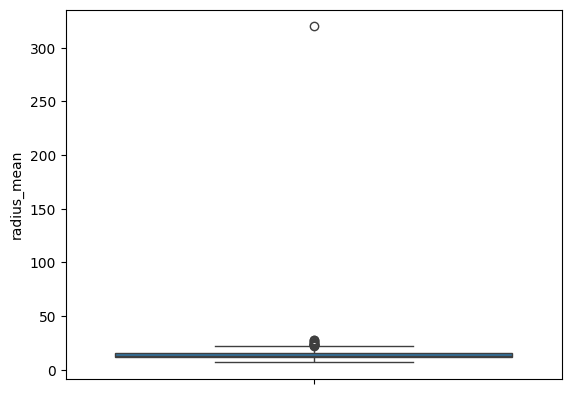

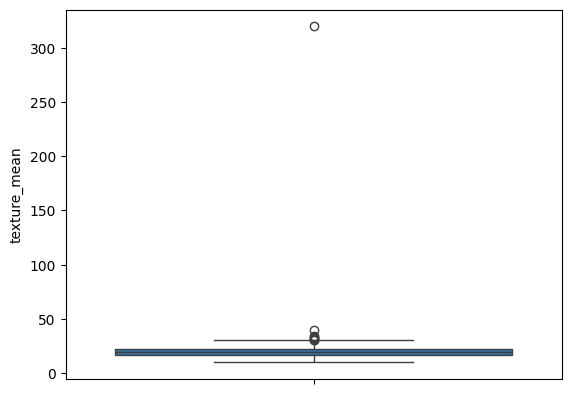

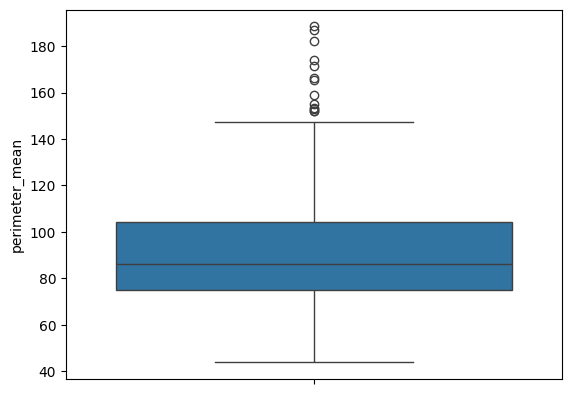

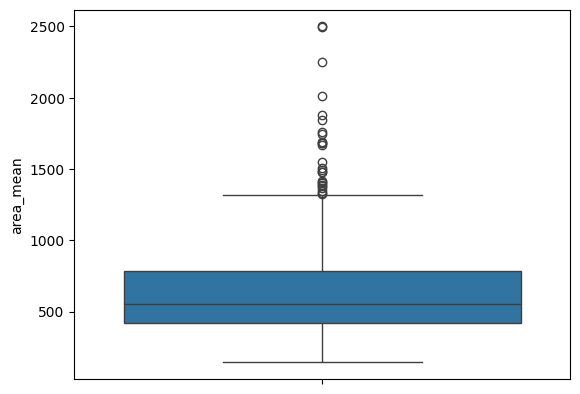

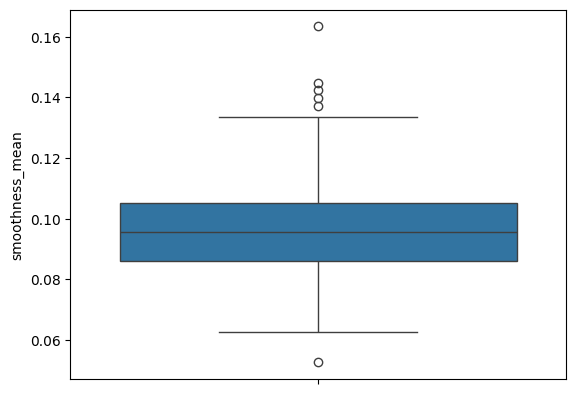

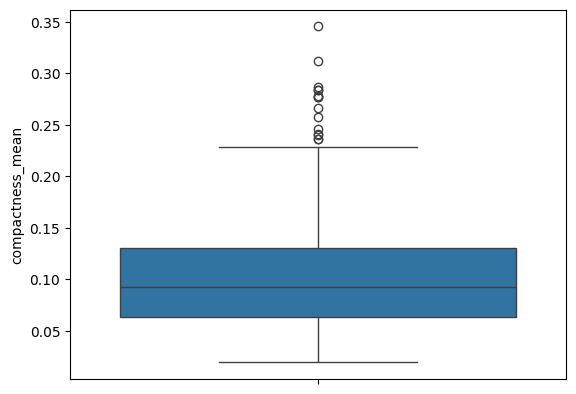

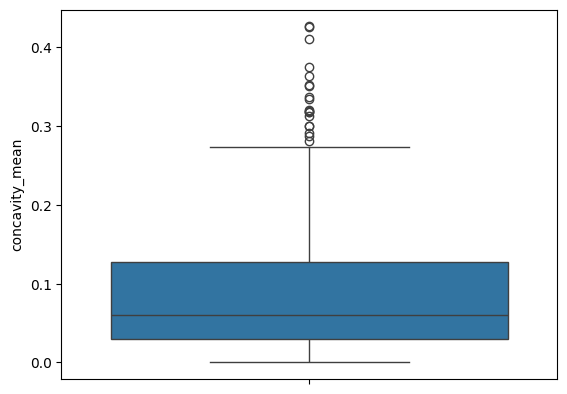

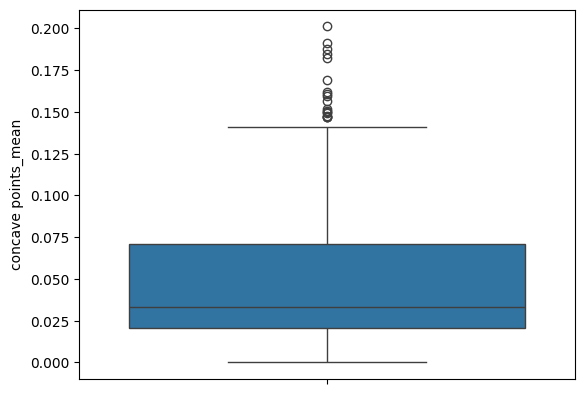

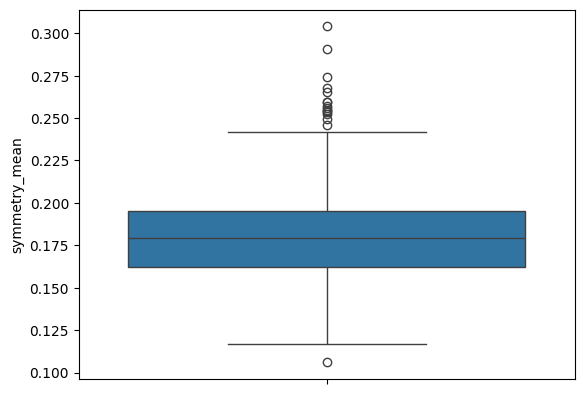

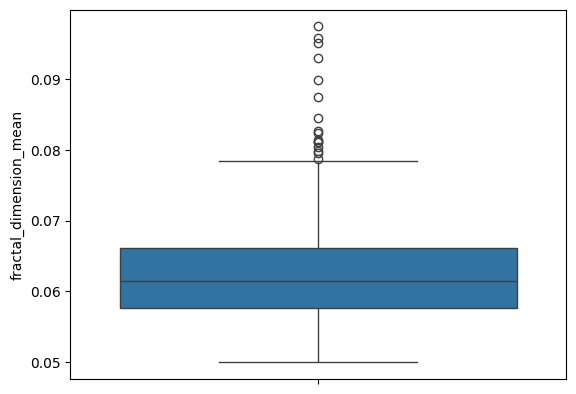

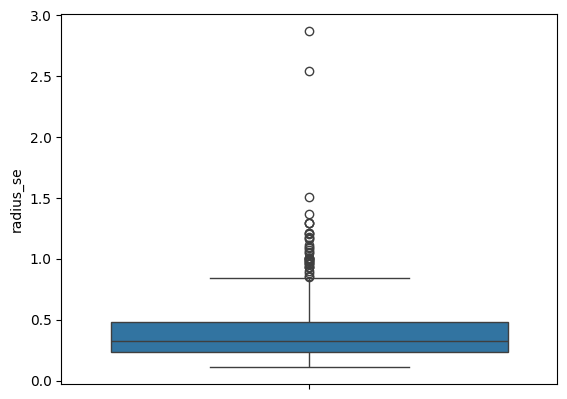

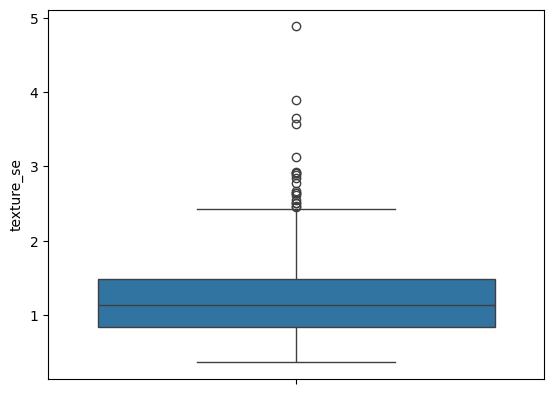

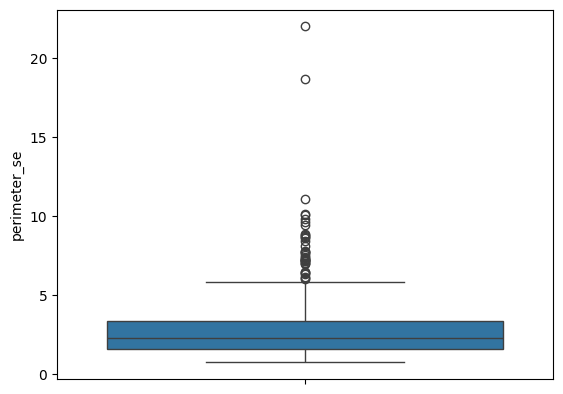

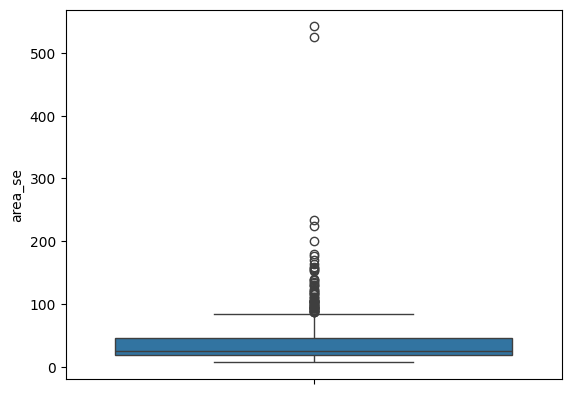

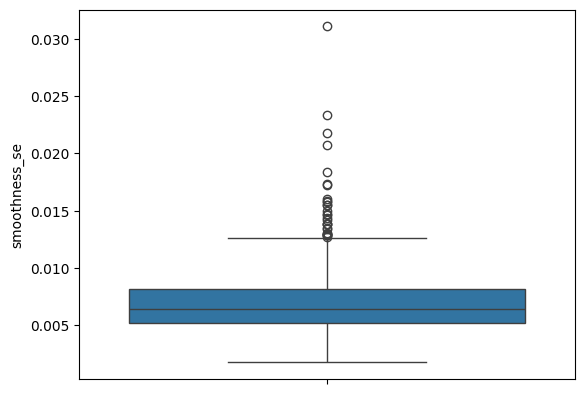

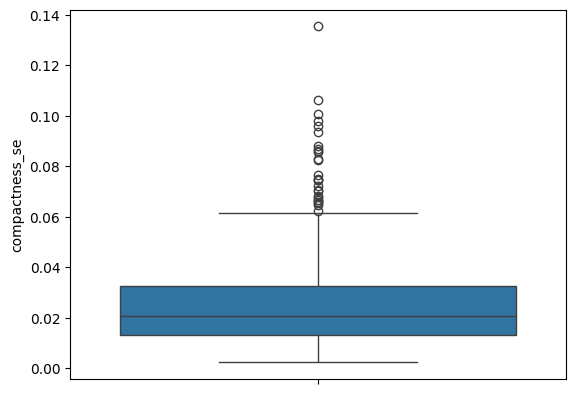

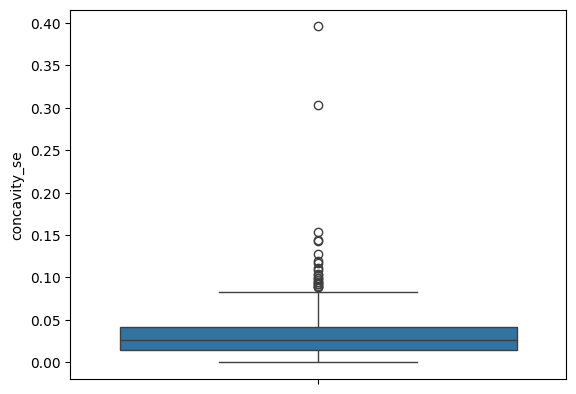

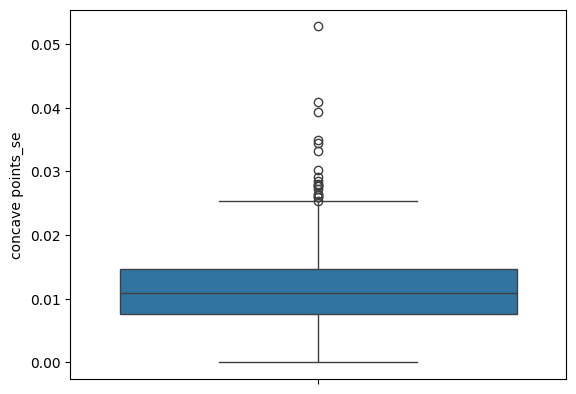

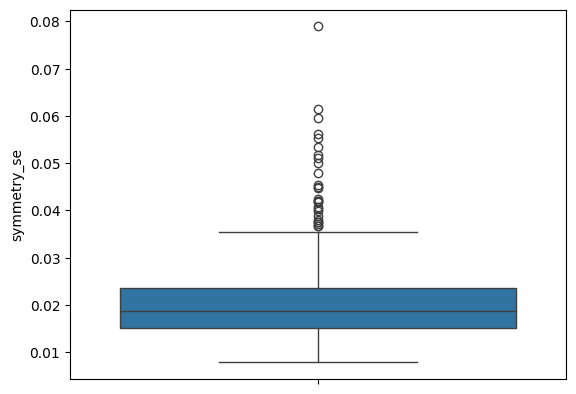

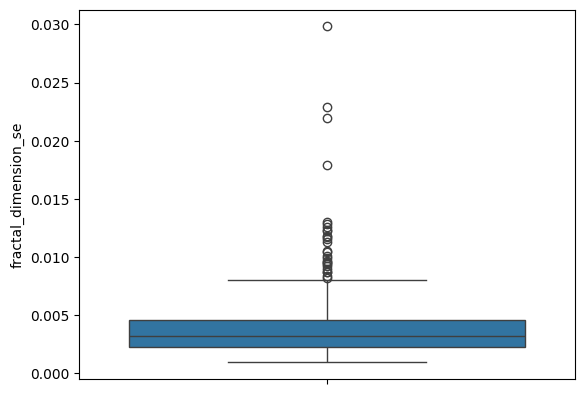

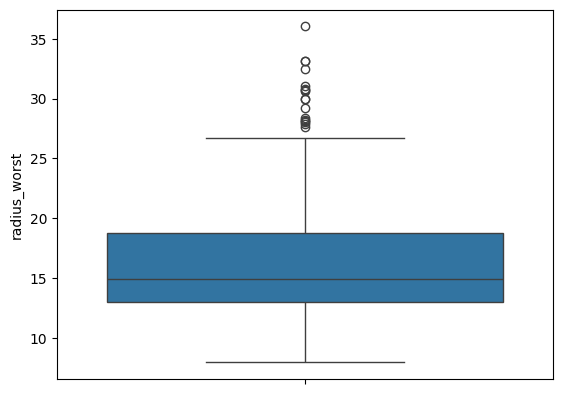

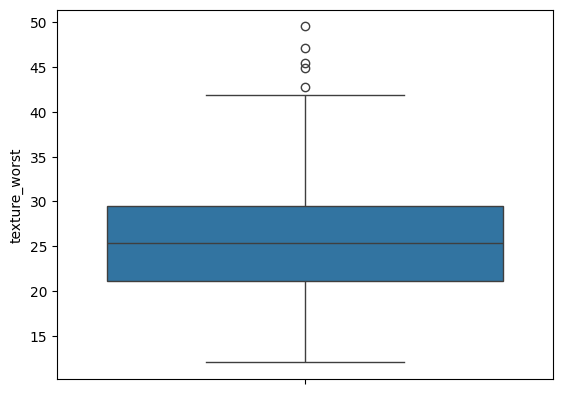

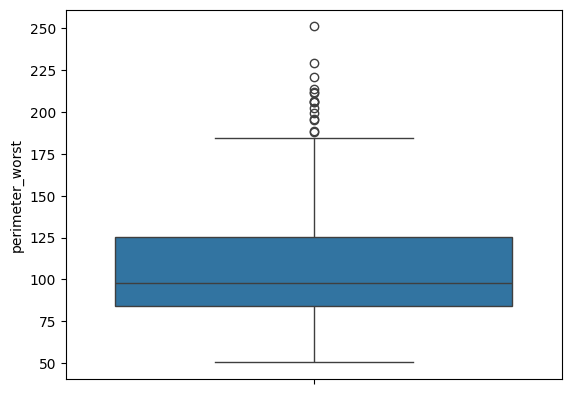

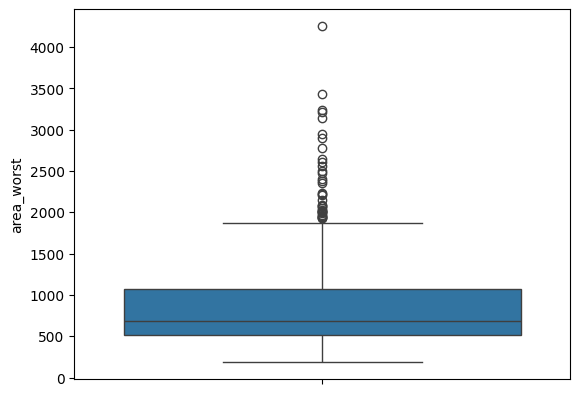

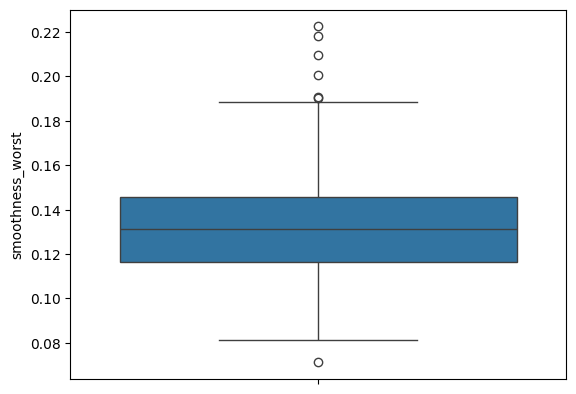

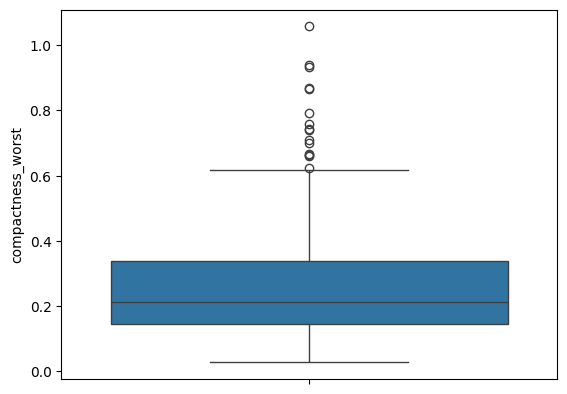

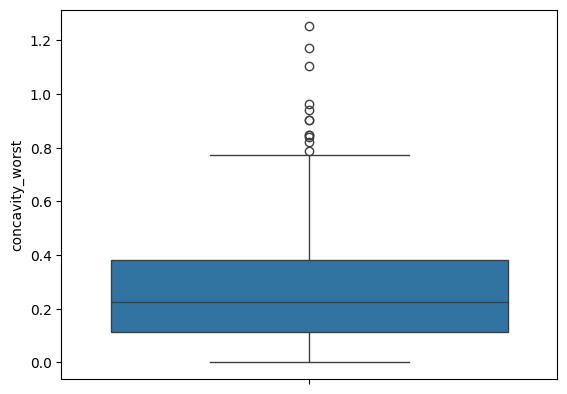

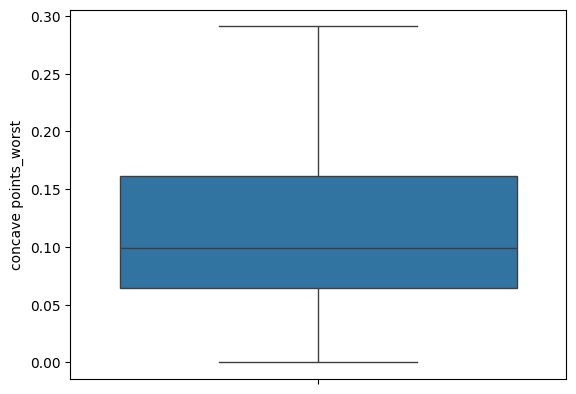

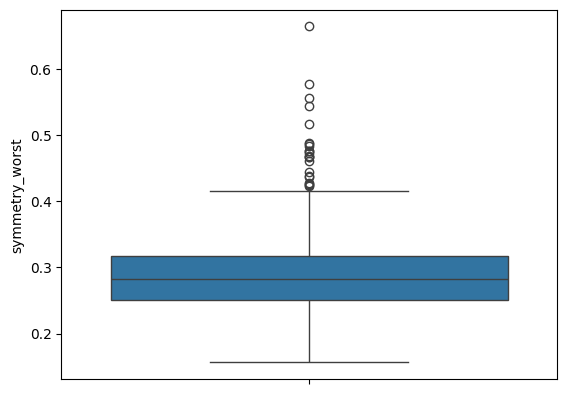

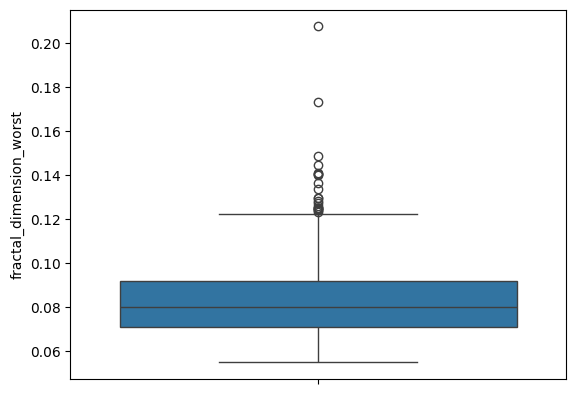

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_feature=df.columns.tolist()
df_feature.remove("id")
df_feature.remove("diagnosis")

for column in df_feature:
   sns.boxplot(df[column])
   plt.show()

This cell specifically generates a box plot for the 'smoothness_worst' column, providing a visual representation of its distribution and potential outliers.

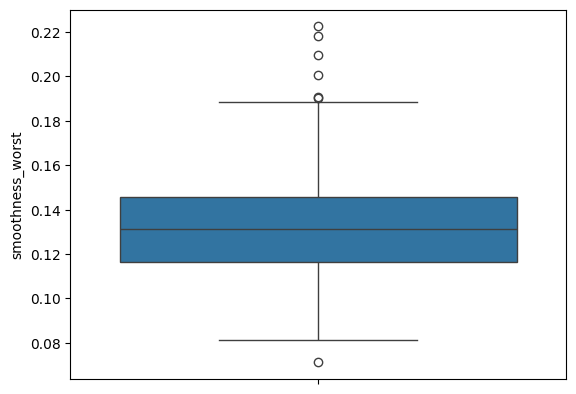

In [ ]:
sns.boxplot(df["smoothness_worst"])
plt.show()

###This cell implements outlier capping using the Interquartile Range (IQR) method. For each numerical feature, it calculates the lower and upper bounds and then clips values that fall outside these bounds. After capping, it generates and displays a new box plot for each feature to visualize the effect of outlier handling.

#HANDLE OUTLIER FOR EVERY FEATURE
Now, let's iterate through each numerical column, apply outlier capping using the IQR method, and then visualize the distribution with a box plot for each.

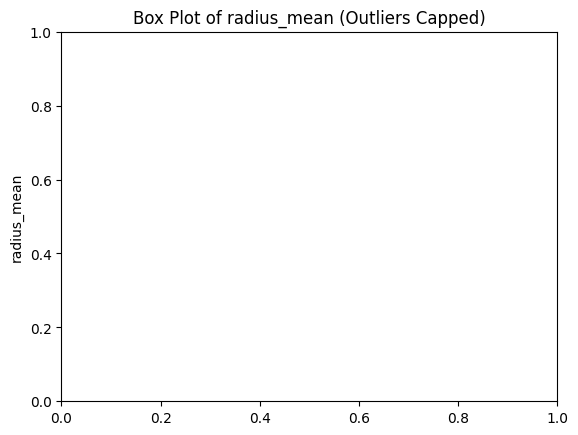

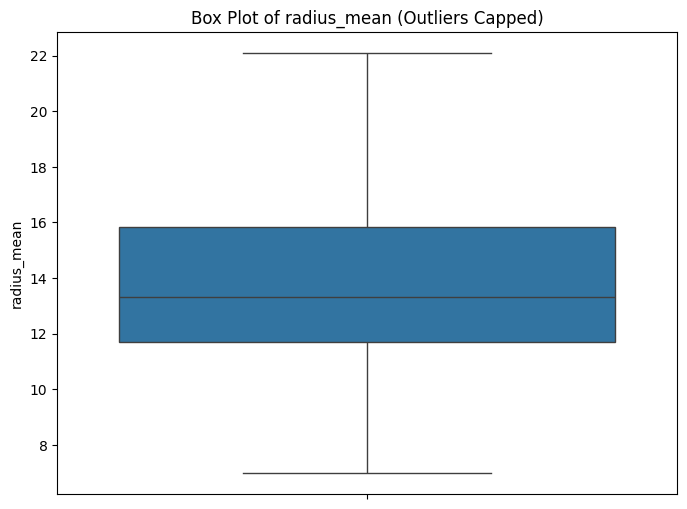

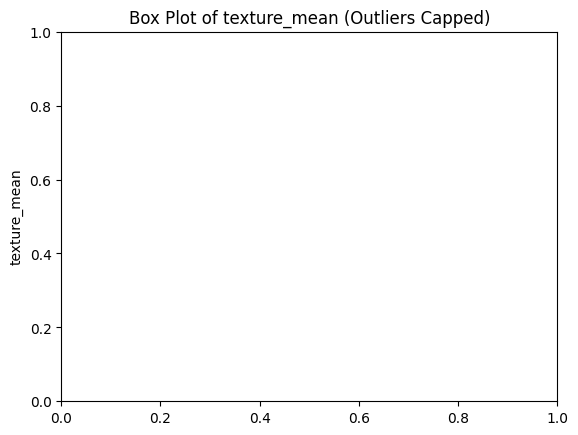

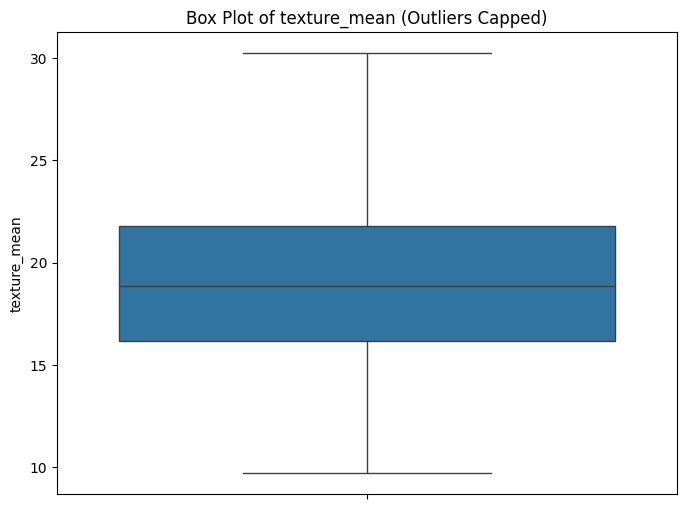

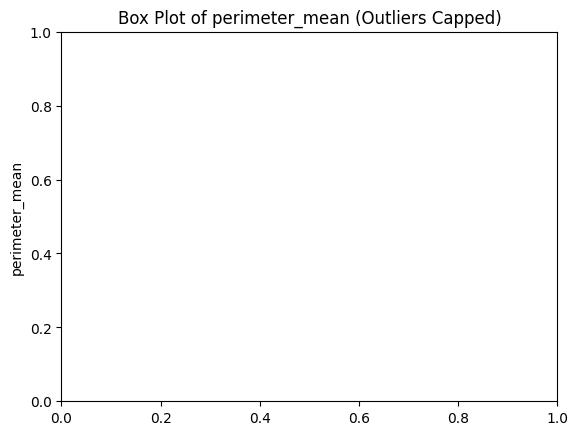

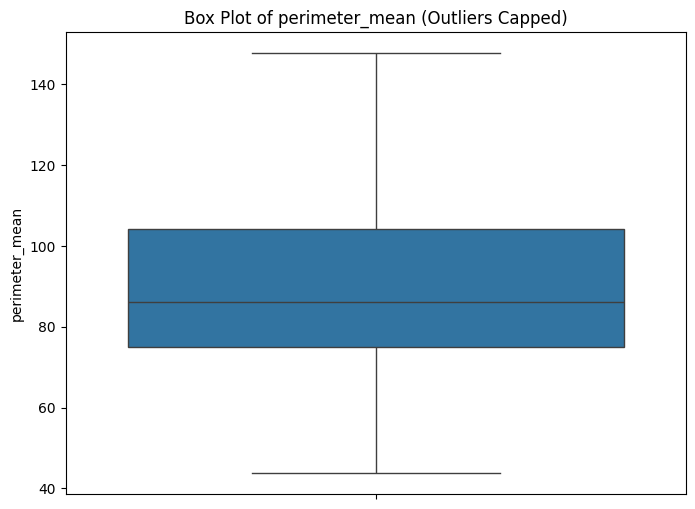

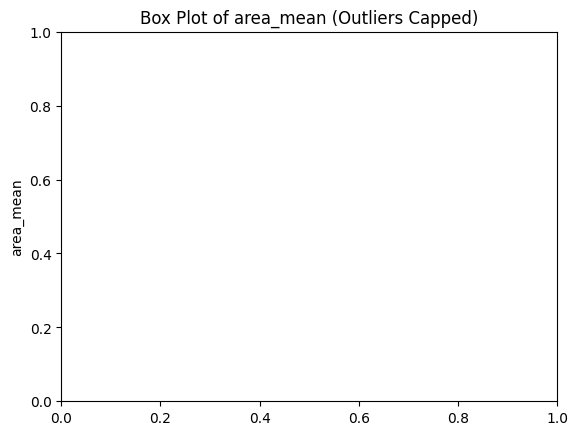

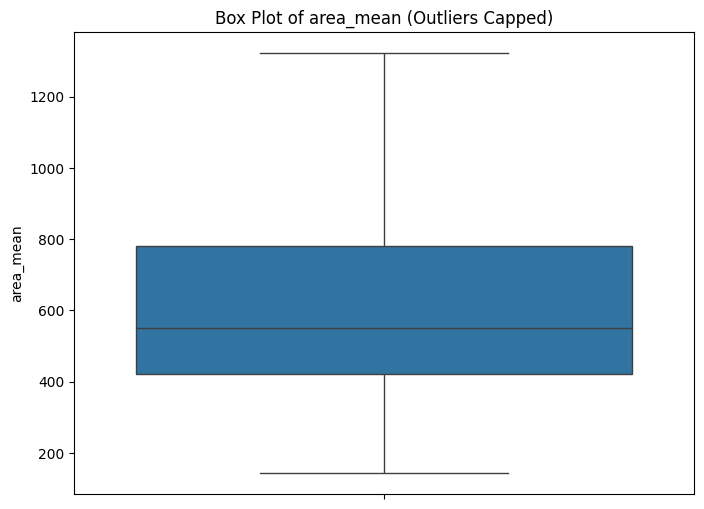

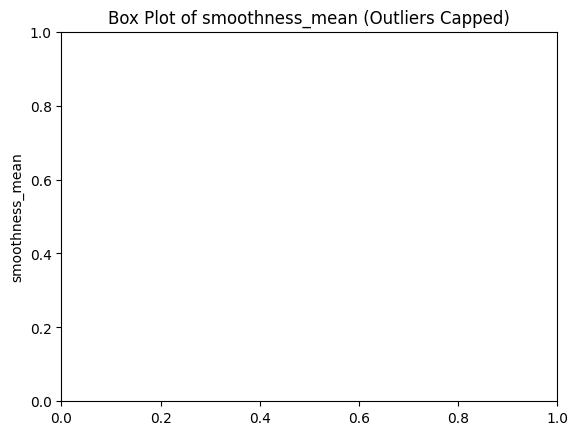

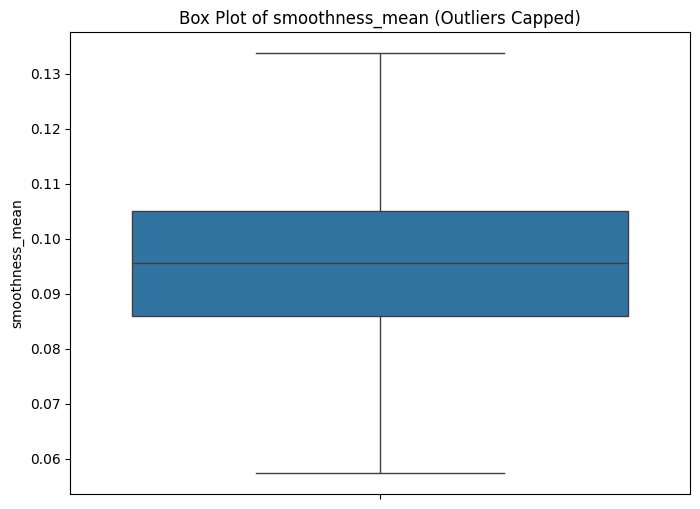

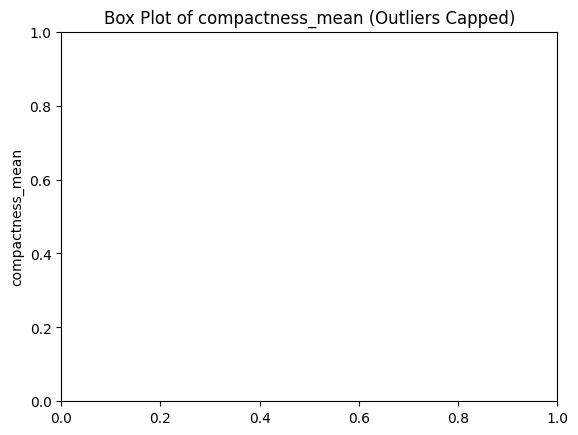

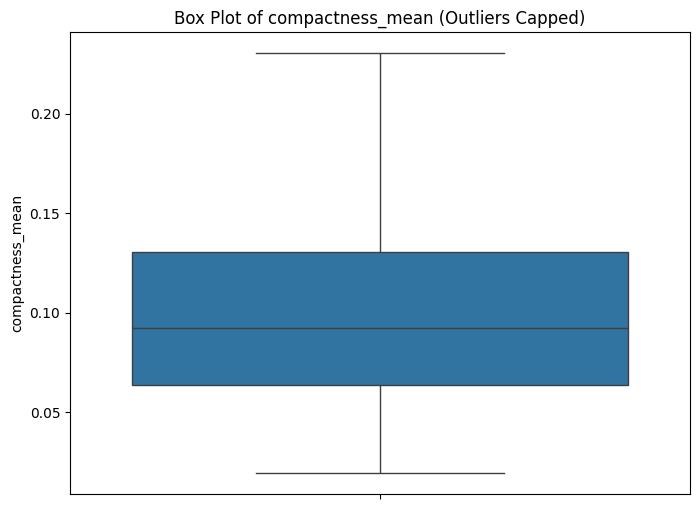

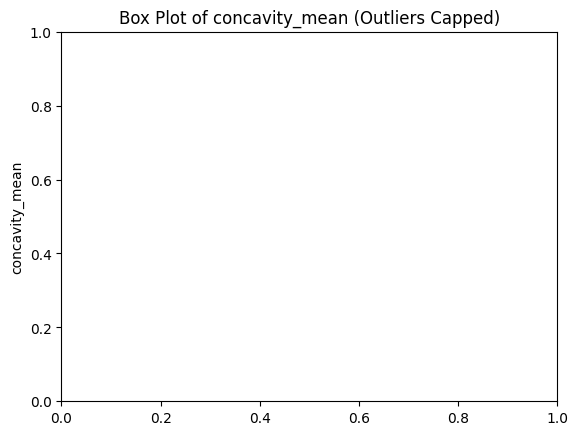

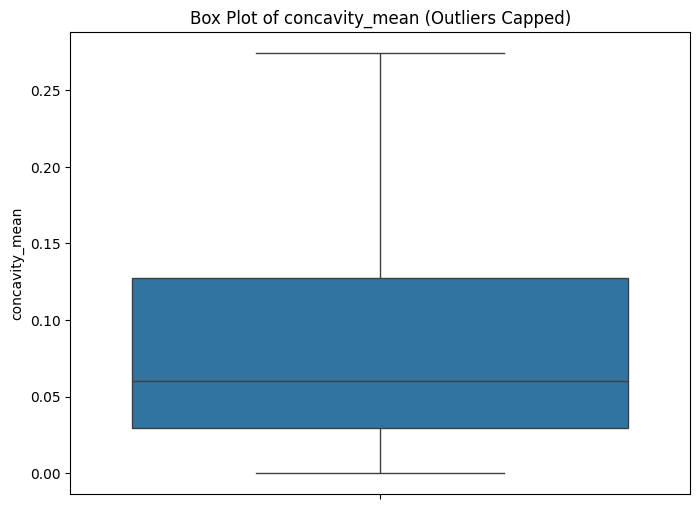

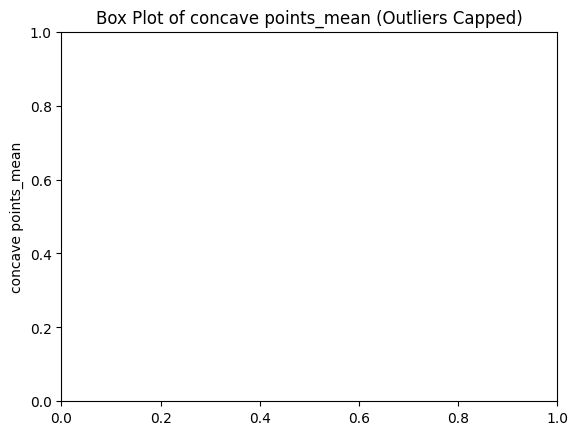

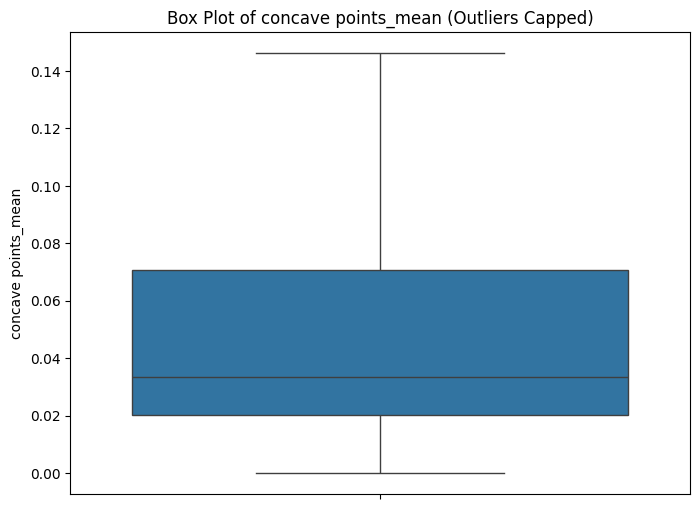

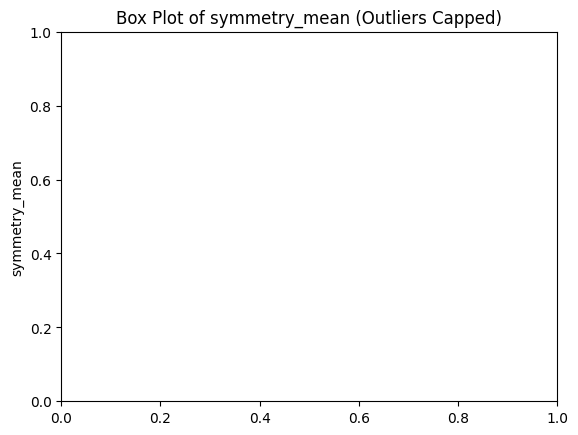

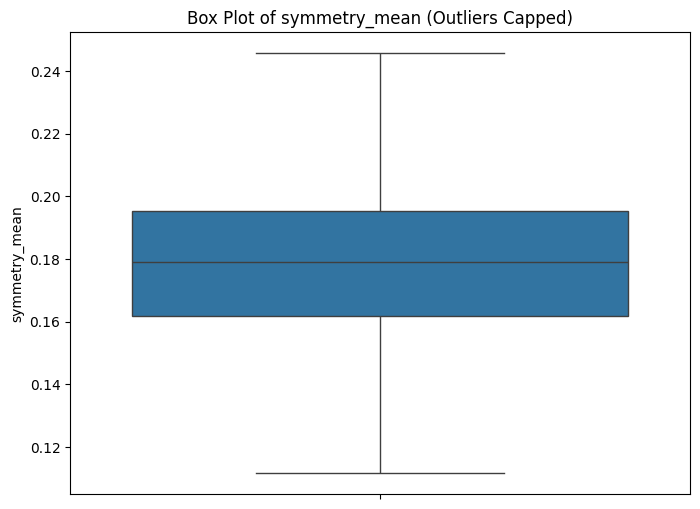

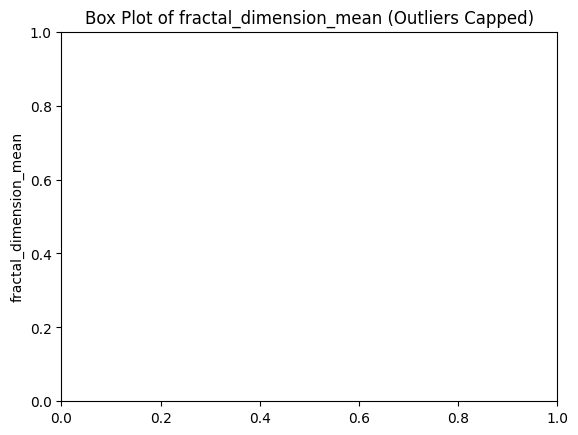

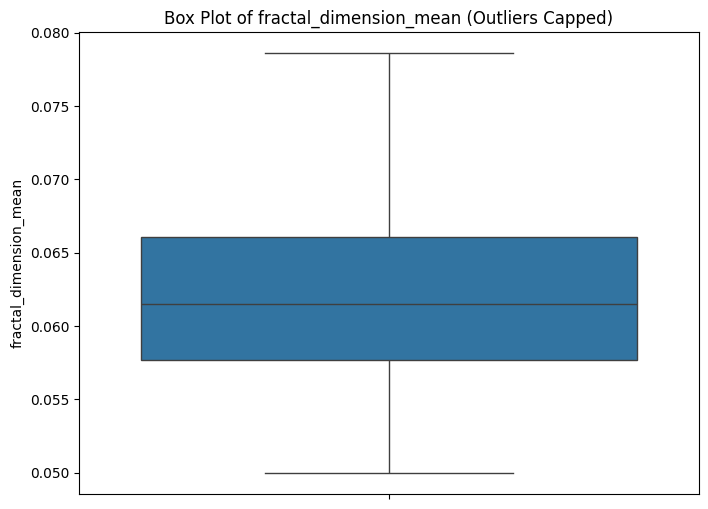

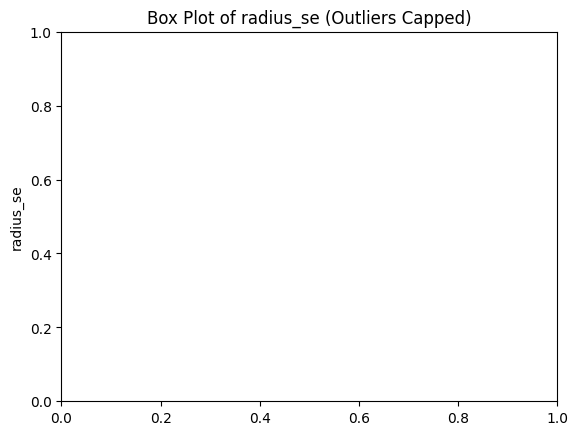

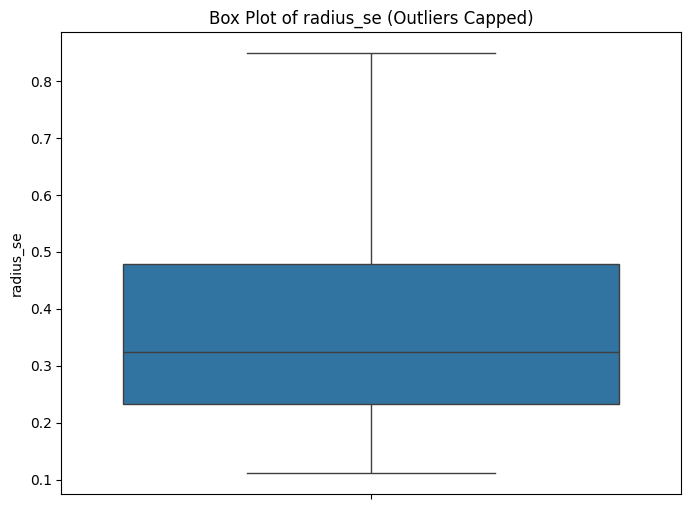

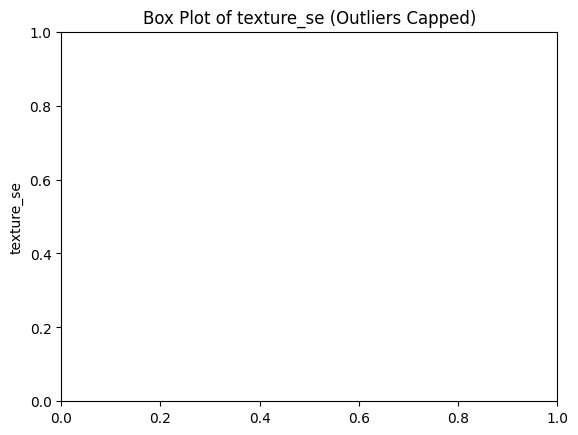

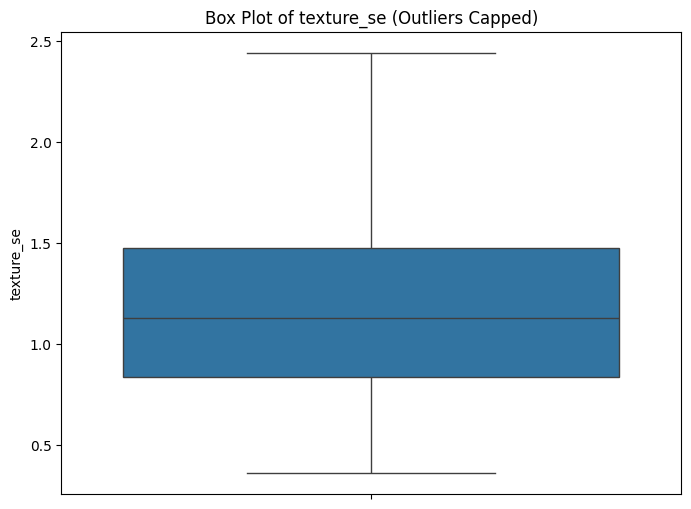

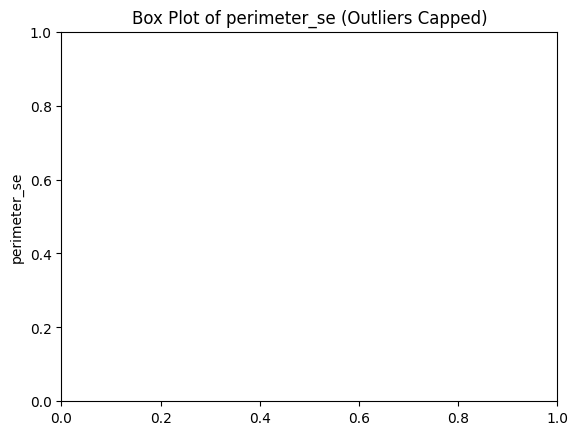

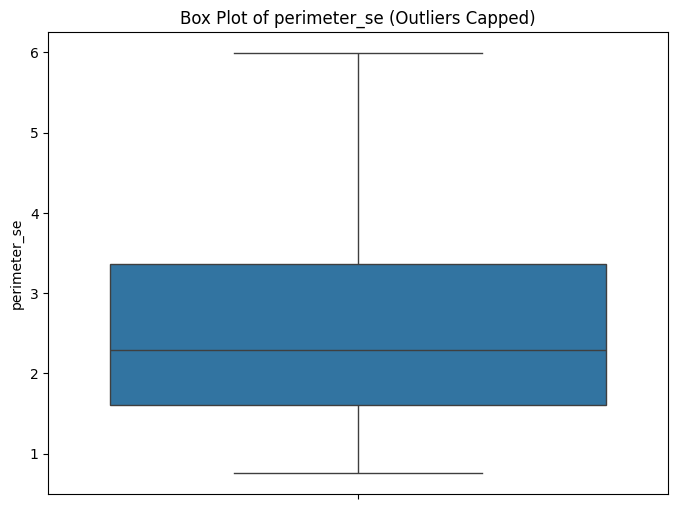

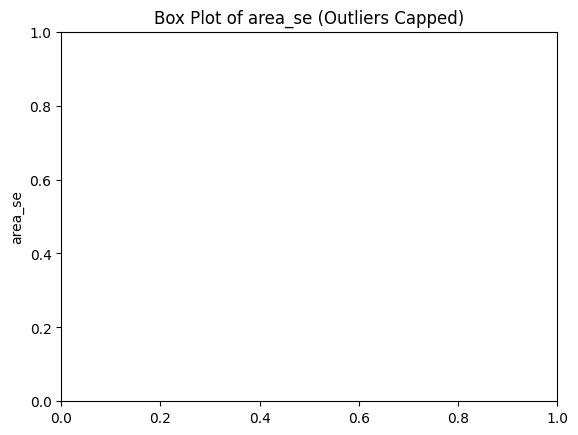

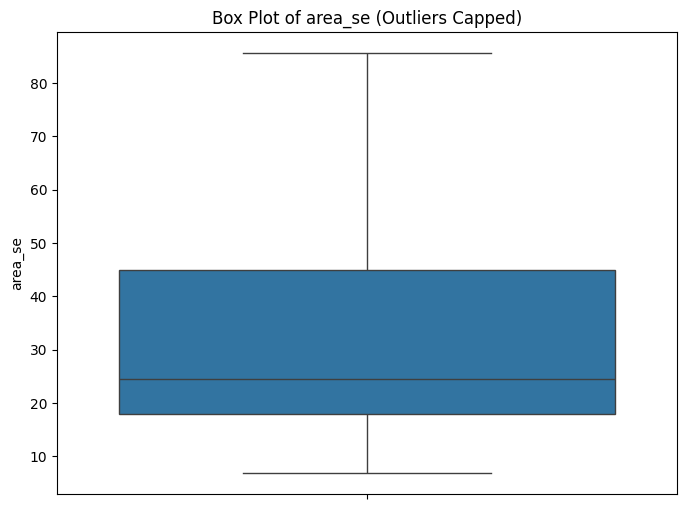

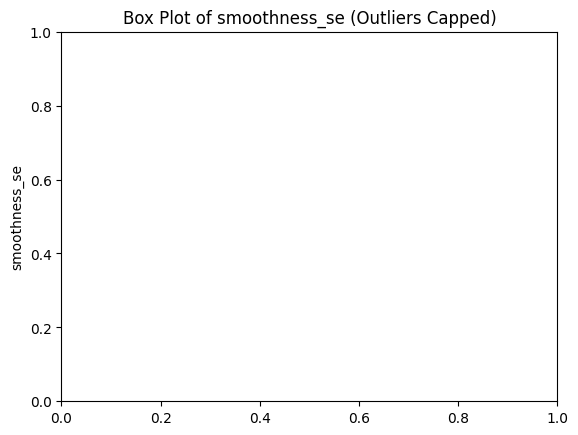

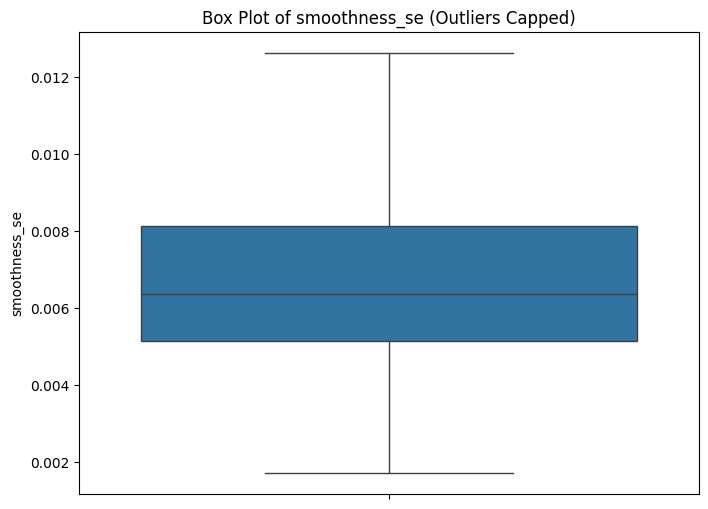

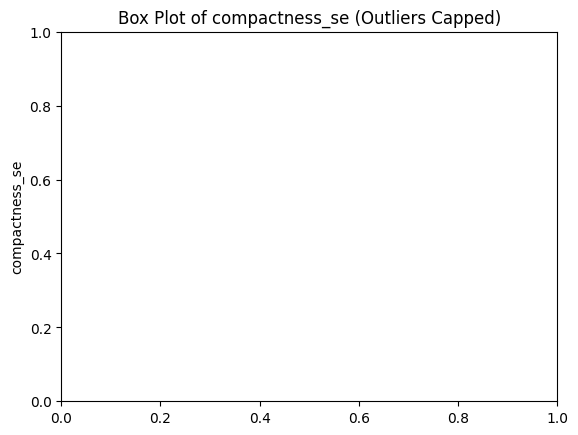

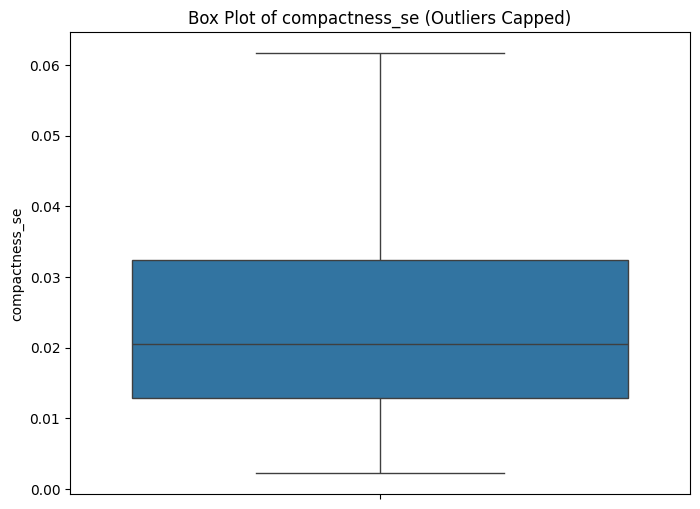

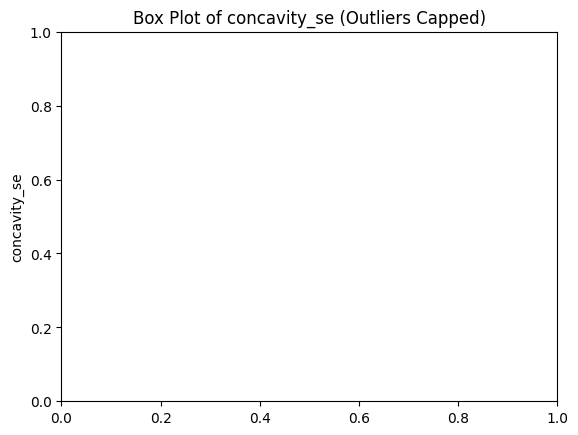

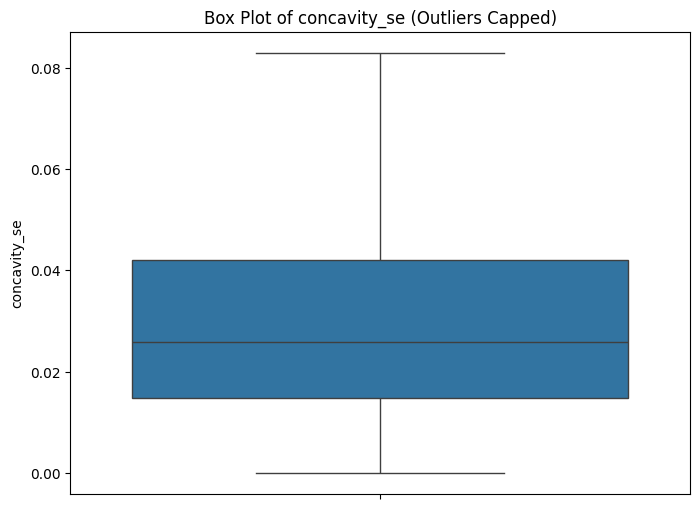

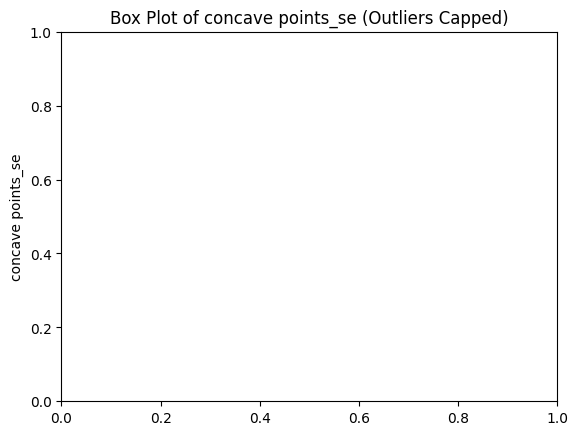

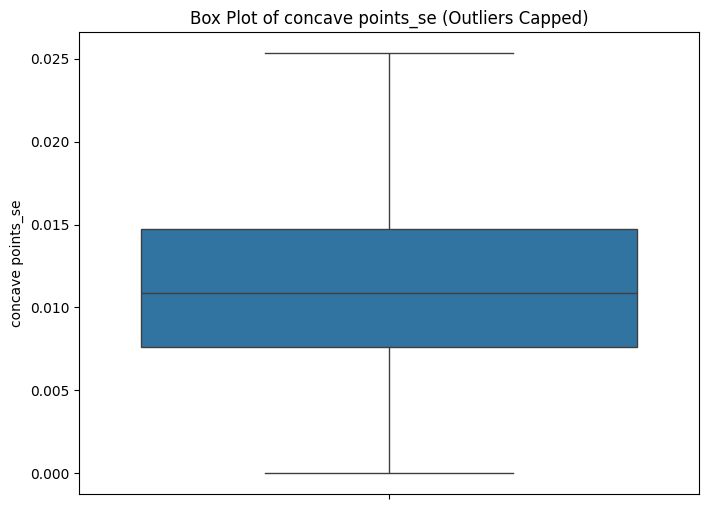

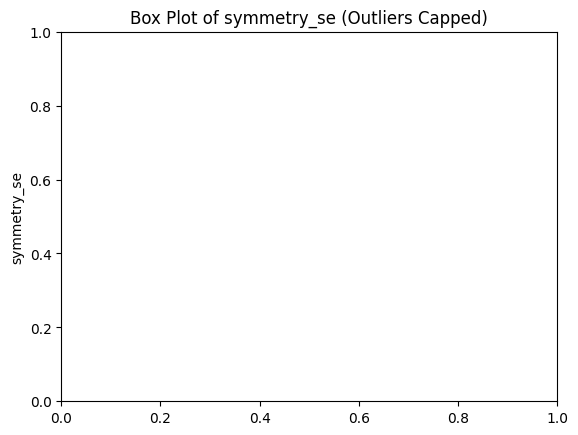

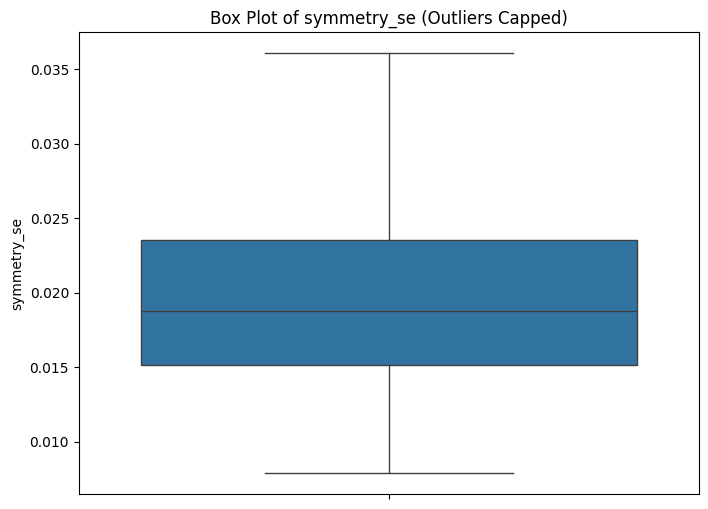

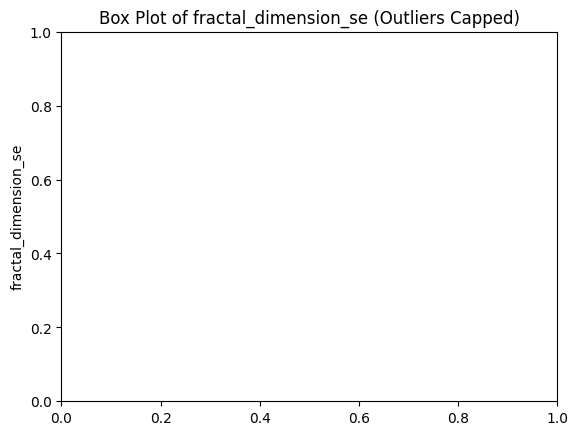

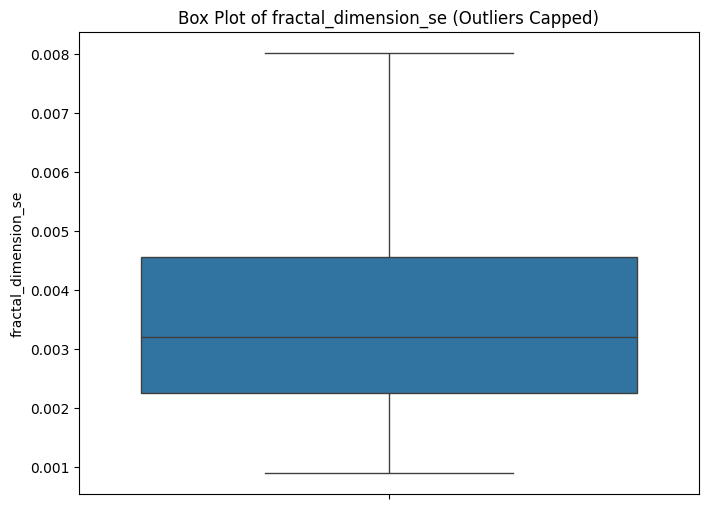

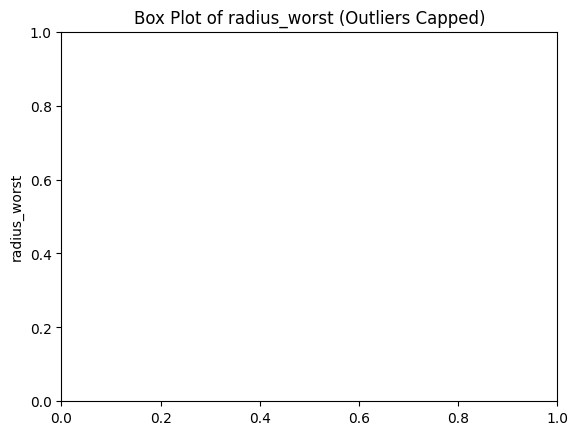

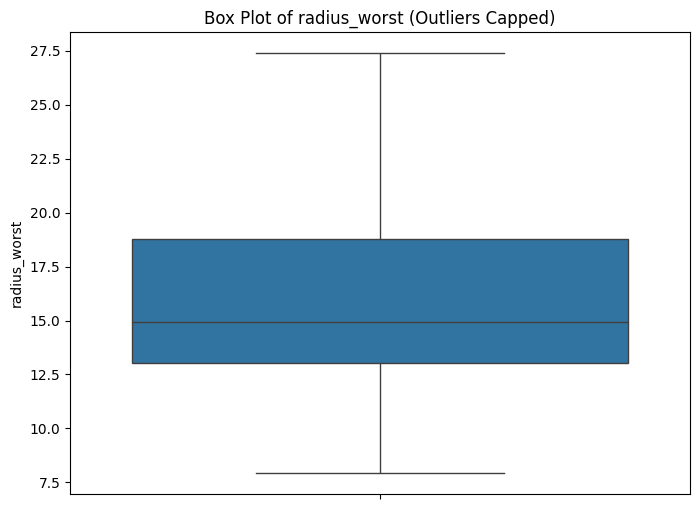

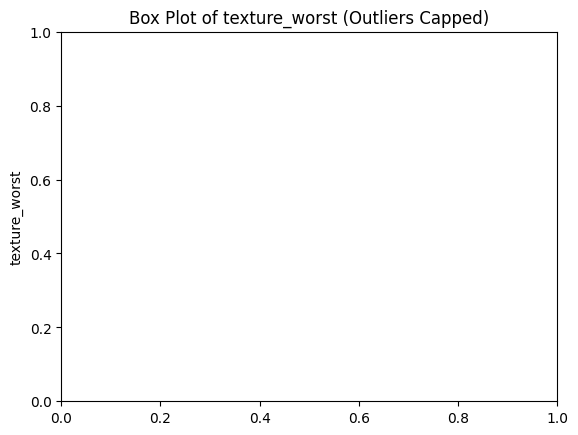

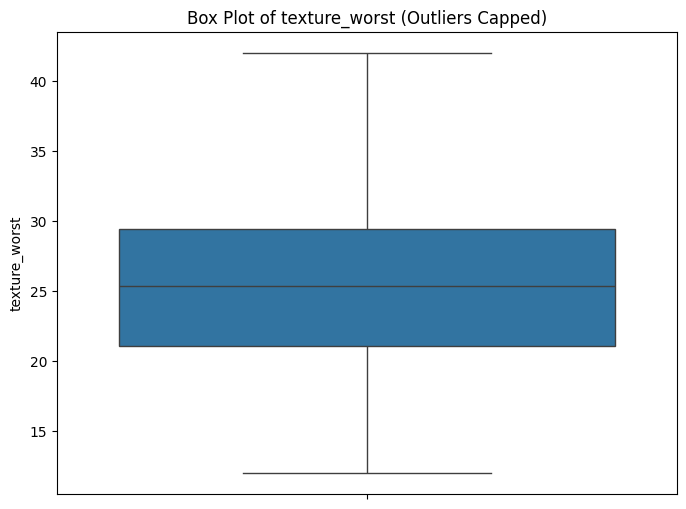

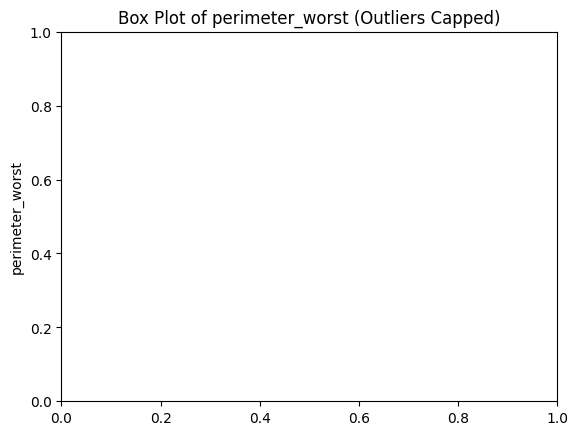

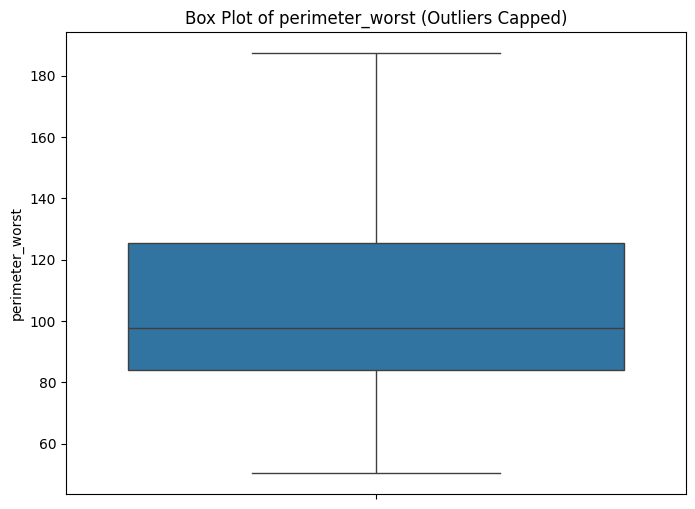

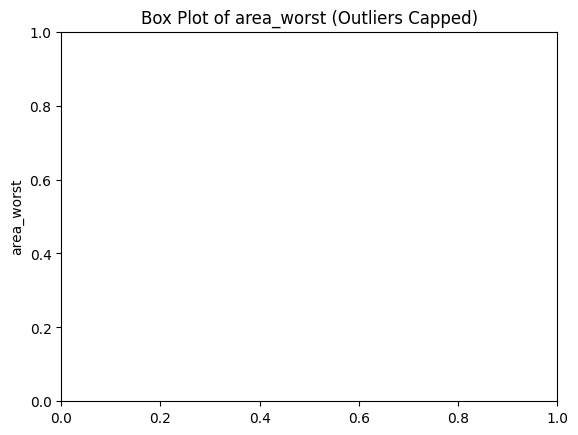

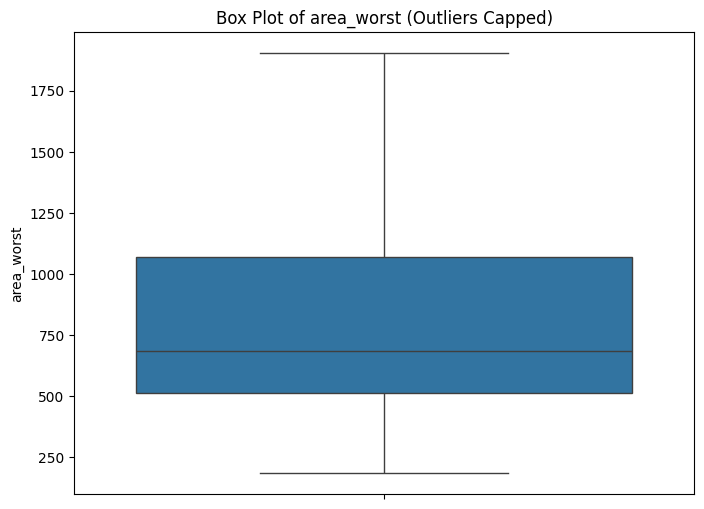

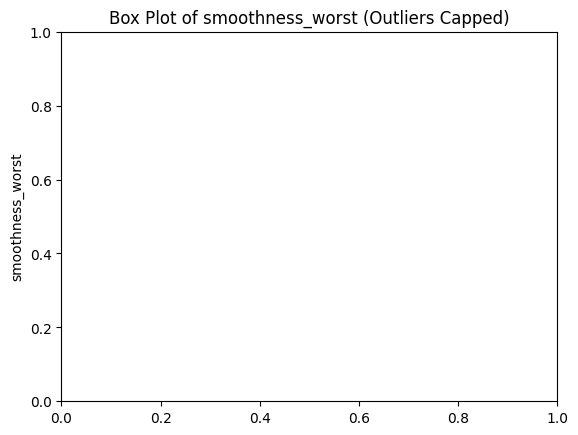

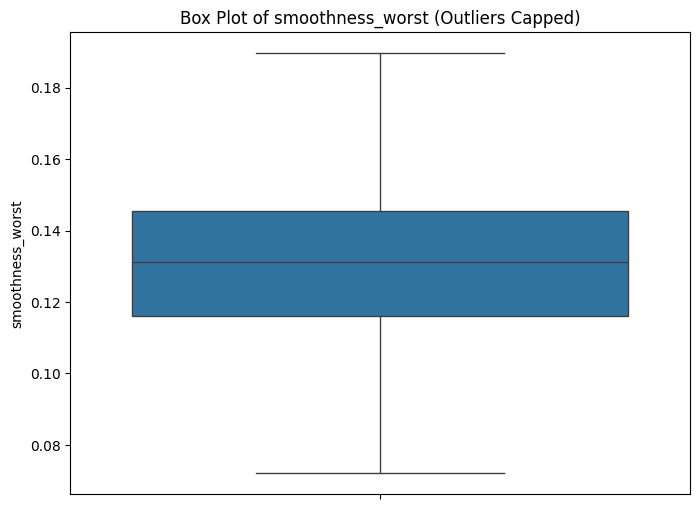

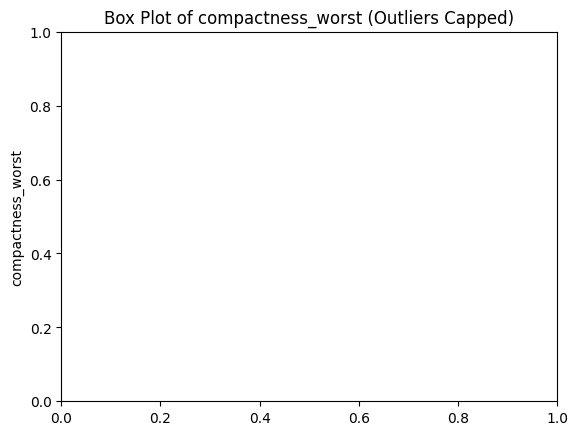

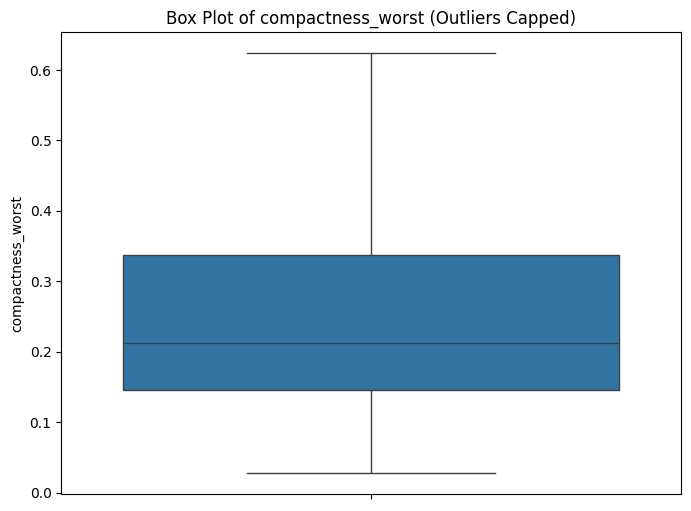

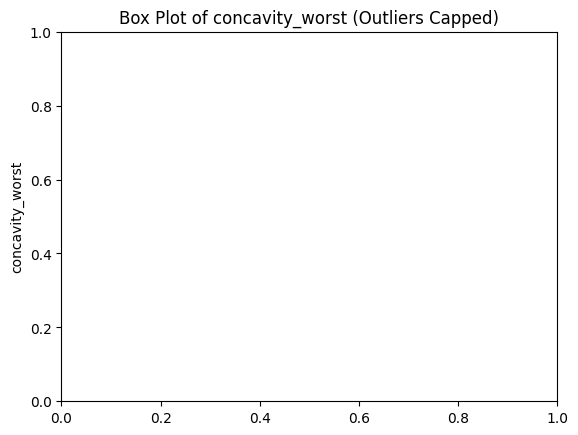

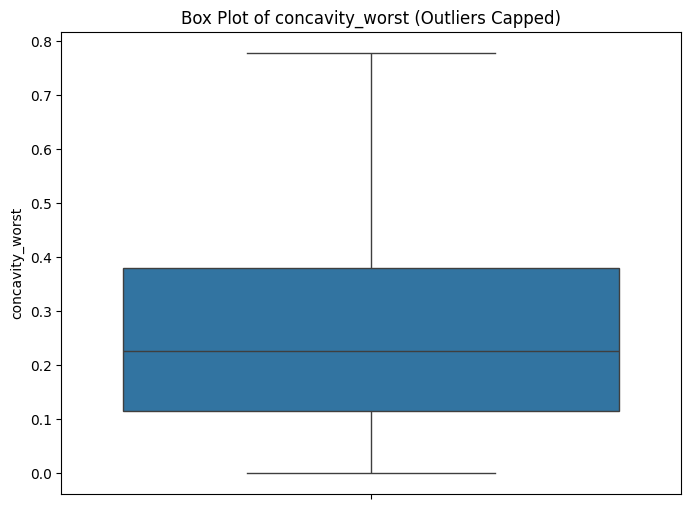

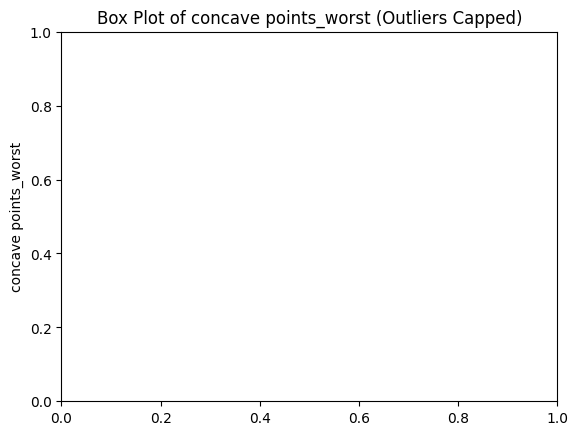

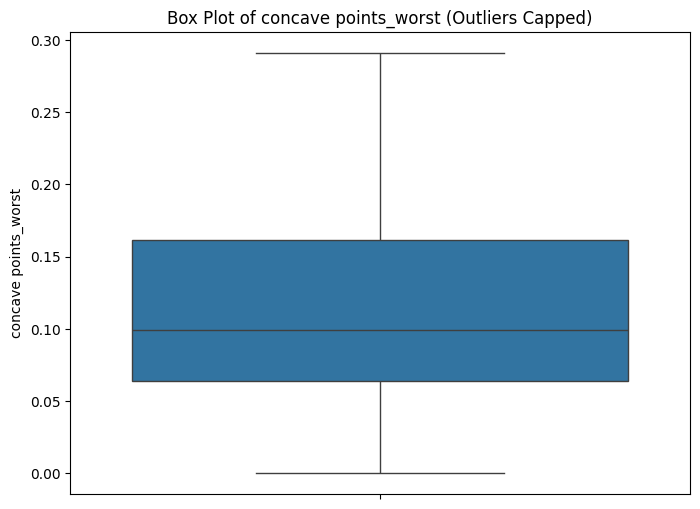

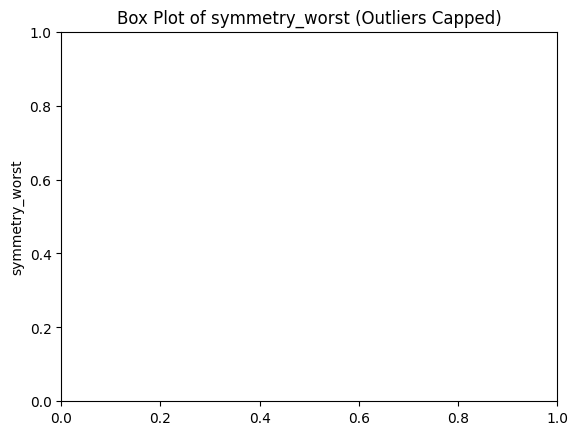

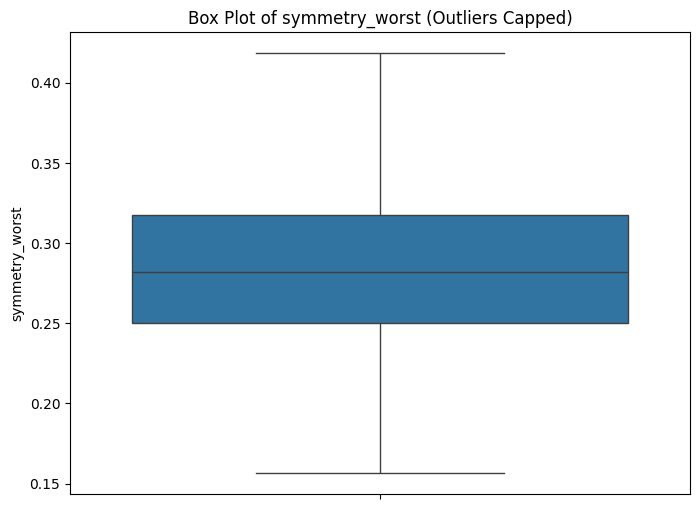

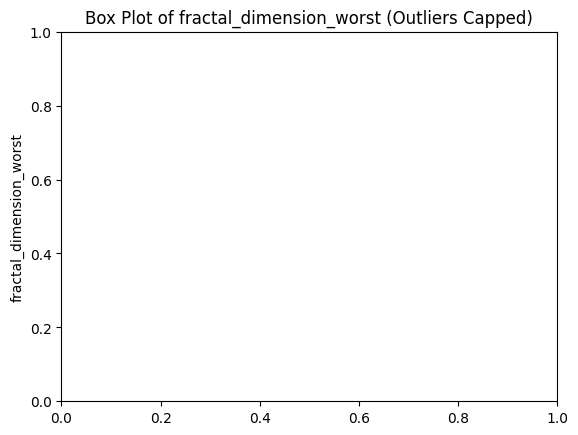

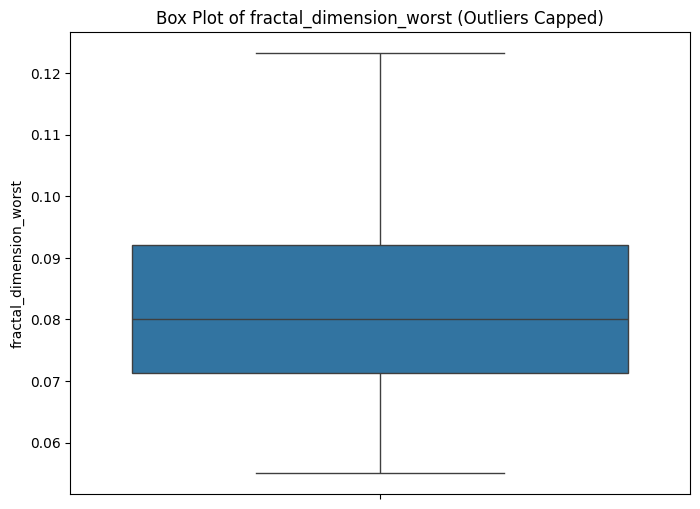

In [ ]:
for column in df_feature:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Apply capping to handle outliers
    df[column] = df[column].clip(lower=lower_bound, upper=upper_bound)

    #Plot boxplot after outlier handling
    plt.title(f'Box Plot of {column} (Outliers Capped)')
    plt.ylabel(column)
    plt.show()
    plt.figure(figsize=(8, 6))
    sns.boxplot(df[column])
    plt.title(f'Box Plot of {column} (Outliers Capped)')
    plt.ylabel(column)
    plt.show()

###This cell appears to be a redundant box plot of the current 'column' being processed, already handled in the previous cell. It will be removed.

This cell performs the crucial step of splitting the dataset into training and testing sets. `X` contains the features (all columns except 'diagnosis' and 'id'), and `y` contains the target variable ('diagnosis'). The data is split with 80% for training and 20% for testing, with `random_state=42` ensuring reproducibility.

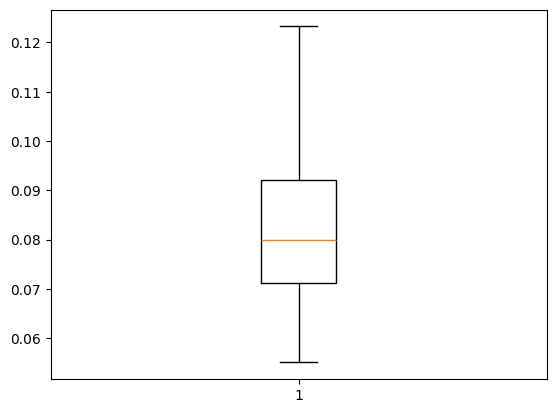

In [ ]:
 # Plot boxplot after outlier handling
 plt.boxplot(df[column])
 plt.show()

#First We do train_test split then we do feature scaling

In [ ]:
from sklearn.model_selection import train_test_split


X=df.drop(["diagnosis"],axis=1)
y=df["diagnosis"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("split succesfully")

split succesfully


This cell initializes a `LabelEncoder` and applies it to the target variable `y`. This converts categorical labels (like 'M' and 'B' for diagnosis) into numerical representations (e.g., 0 and 1), which is required for most machine learning algorithms.

# LABEL ENCODED

In [ ]:
from sklearn.preprocessing import LabelEncoder
# 2. Scale/Encode the Labels (y) to integers (0, 1, etc.)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

###This cell performs feature scaling using `StandardScaler`. It fits the scaler to the training data (`X_train`) to learn the mean and standard deviation, then transforms both the training (`X_train`) and testing (`X_test`) data. Scaling is important for algorithms sensitive to feature magnitudes, like Logistic Regression and K-Nearest Neighbors.

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

###This cell trains and evaluates several classification models: Decision Tree, Logistic Regression, Random Forest, and K-Nearest Neighbors. It first instantiates each model, then encodes the `y_train` and `y_test` data using the previously fitted `LabelEncoder`. After training, it makes predictions on the scaled test set and prints key performance metrics (Accuracy, Precision, Recall, F1 Score) for each model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


dt=DecisionTreeClassifier(random_state=42)
lr=LogisticRegression(random_state=42)
rf=RandomForestClassifier(random_state=42)
knn=KNeighborsClassifier()

# Encode y_train and y_test
y_train_encoded = le.transform(y_train)
y_test_encoded = le.transform(y_test)

dt.fit(X_train_scaled, y_train_encoded)
lr.fit(X_train_scaled, y_train_encoded)
rf.fit(X_train_scaled, y_train_encoded)
knn.fit(X_train_scaled, y_train_encoded)

y_pred_dt=dt.predict(X_test_scaled)
y_pred_lr=lr.predict(X_test_scaled)
y_pred_rf=rf.predict(X_test_scaled)
y_pred_knn=knn.predict(X_test_scaled)

print("Decision Tree")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_dt))
print("Precision:", precision_score(y_test_encoded, y_pred_dt))
print("Recall:", recall_score(y_test_encoded, y_pred_dt))
print("F1 Score:", f1_score(y_test_encoded, y_pred_dt))

print("\nLogistic Regression")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_lr))
print("Precision:", precision_score(y_test_encoded, y_pred_lr))
print("Recall:", recall_score(y_test_encoded, y_pred_lr))
print("F1 Score:", f1_score(y_test_encoded, y_pred_lr))

print("\nRandom Forest")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_rf))
print("Precision:", precision_score(y_test_encoded, y_pred_rf))
print("Recall:", recall_score(y_test_encoded, y_pred_rf))
print("F1 Score:", f1_score(y_test_encoded, y_pred_rf))

print("\nK-Nearest Neighbors")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_knn))
print("Precision:", precision_score(y_test_encoded, y_pred_knn))
print("Recall:", recall_score(y_test_encoded, y_pred_knn))
print("F1 Score:", f1_score(y_test_encoded, y_pred_knn))

Decision Tree
Accuracy: 0.911504424778761
Precision: 0.8863636363636364
Recall: 0.8863636363636364
F1 Score: 0.8863636363636364

Logistic Regression
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Random Forest
Accuracy: 0.9203539823008849
Precision: 0.9487179487179487
Recall: 0.8409090909090909
F1 Score: 0.891566265060241

K-Nearest Neighbors
Accuracy: 0.9380530973451328
Precision: 0.9743589743589743
Recall: 0.8636363636363636
F1 Score: 0.9156626506024096


###This cell calculates and stores the performance metrics (Accuracy, Precision, Recall, F1 Score) for each of the trained models into a pandas DataFrame called `performance_df`. This structured format makes it easy to compare the models' performance.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a dictionary to store model performance metrics
performance_data = {
    'Model': ['Decision Tree', 'Logistic Regression', 'Random Forest', 'K-Nearest Neighbors'],
    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred_dt),
        accuracy_score(y_test_encoded, y_pred_lr),
        accuracy_score(y_test_encoded, y_pred_rf),
        accuracy_score(y_test_encoded, y_pred_knn)
    ],
    'Precision': [
        precision_score(y_test_encoded, y_pred_dt),
        precision_score(y_test_encoded, y_pred_lr),
        precision_score(y_test_encoded, y_pred_rf),
        precision_score(y_test_encoded, y_pred_knn)
    ],
    'Recall': [
        recall_score(y_test_encoded, y_pred_dt),
        recall_score(y_test_encoded, y_pred_lr),
        recall_score(y_test_encoded, y_pred_rf),
        recall_score(y_test_encoded, y_pred_knn)
    ],
    'F1 Score': [
        f1_score(y_test_encoded, y_pred_dt),
        f1_score(y_test_encoded, y_pred_lr),
        f1_score(y_test_encoded, y_pred_rf),
        f1_score(y_test_encoded, y_pred_knn)
    ]
}

# Create a DataFrame from the performance data
performance_df = pd.DataFrame(performance_data)

display(performance_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.911504,0.886364,0.886364,0.886364
1,Logistic Regression,1.000000,1.000000,1.000000,1.000000
2,Random Forest,0.920354,0.948718,0.840909,0.891566
3,K-Nearest Neighbors,0.938053,0.974359,0.863636,0.915663


###This cell visualizes the performance metrics of the different models using bar plots. It iterates through each metric (Accuracy, Precision, Recall, F1 Score) and generates a bar plot

Let's visualize these metrics using bar plots for easier comparison.

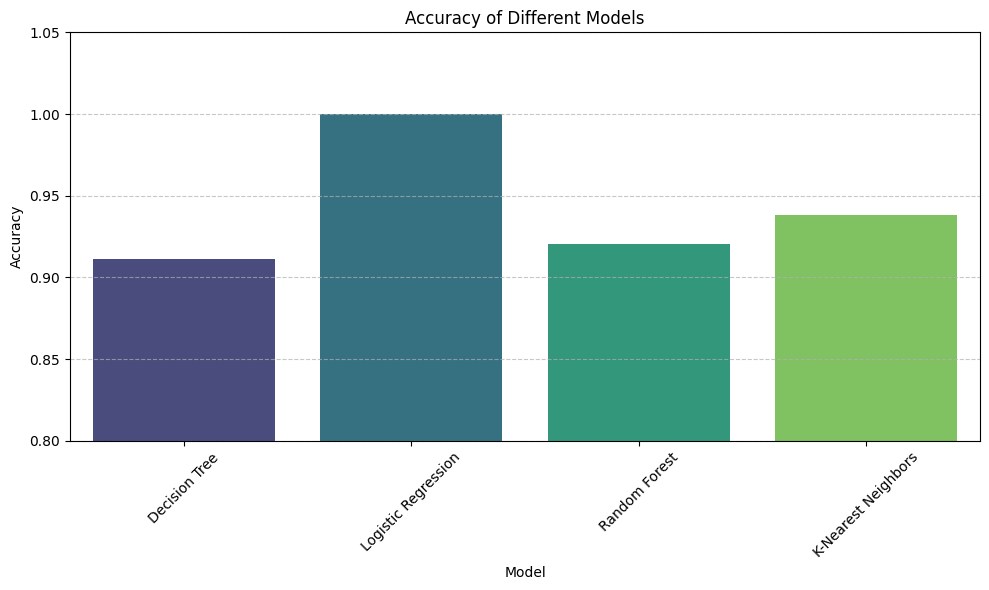

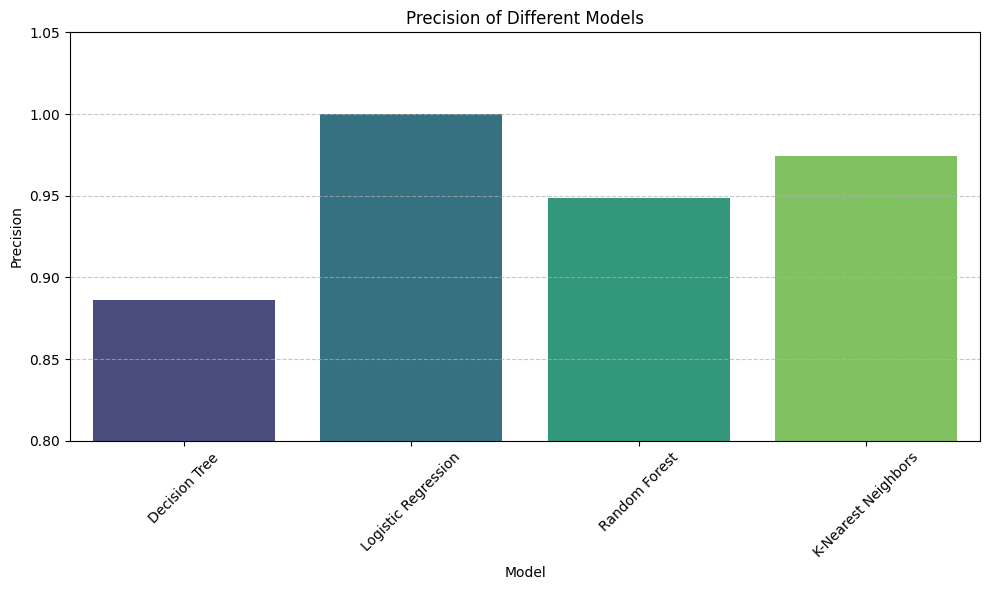

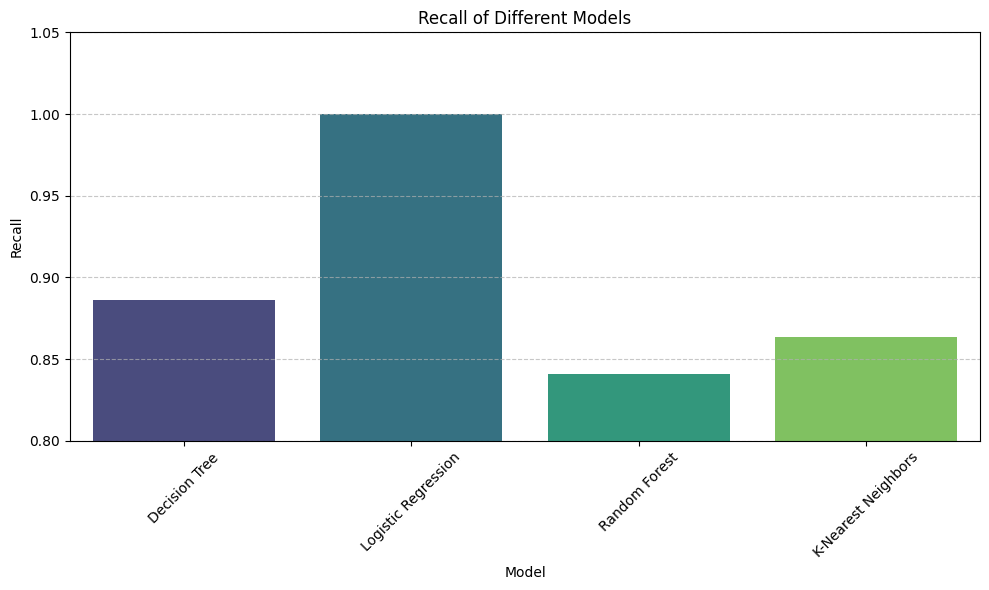

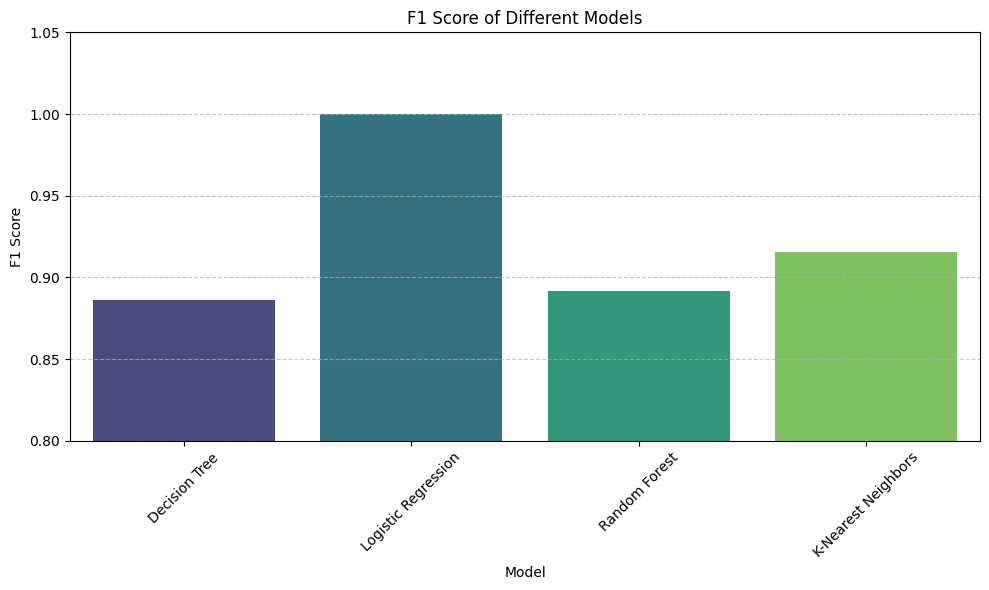

In [ ]:
# Plotting the performance metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for metric in metrics:
    plt.figure(figsize=(10, 6))
    # Corrected usage of palette with hue for future compatibility
    sns.barplot(x='Model', y=metric, data=performance_df, hue='Model', palette='viridis', legend=False)
    plt.title(f'{metric} of Different Models')
    plt.ylim(0.8, 1.05) # Set y-limit to better show differences for high scores
    plt.ylabel(metric)
    plt.xlabel('Model')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()